# Hafta 02: Ağın Mimarisi, Cihaz Rolleri, Paket Anahtarlama ve Protokol Hiyerarşisi

> **Ders Kitabı Referansı:** Computer Networking: A Top-Down Approach (J.F. Kurose, K.W. Ross — Bölüm 1)

---

## 1. Temel Kavramlar ve Mimari Zemin

### 1.1. İnternet Nedir? (Uç Sistemler ve Ağın Çekirdeği)
İnternet; dünya çapında yüz milyonlarca bilgi-işlem cihazını birbirine bağlayan, paket anahtarlamalı devasa bir ağlar ağıdır (Network of Networks).

1. **Uç Sistemler (End Systems / Hosts):** Ağın sınırında (Edge) yer alan istemciler (PC, akıllı telefon, tablet, IoT sensörleri) ve sunuculardır. Ağ uygulamaları (Web, e-posta, veritabanı, mobil backend) **yalnızca uç sistemlerde çalışır**. Ağın içindeki cihazlar uygulama kodunu çalıştırmaz; görevi yalnızca veriyi taşımaktır.
2. **İletişim Bağlantıları (Communication Links):** Verinin aktığı fiziksel kanallardır. Bakır kablo (Twisted-Pair), Koaksiyel kablo, Fiber optik ve Kablosuz (Wi-Fi, hücresel 4G/5G, uydu) ortamlar kullanılır. İletim kapasitesi **bit/saniye (bps)** ile ölçülür.
3. **Paket Anahtarlayıcılar (Packet Switches):** Gelen veri paketlerini ara bağlantılardan geçirerek hedefe yönlendiren cihazlardır (Switch ve Router).

---

### 1.2. Ağ Cihazları Arasındaki Temel Fark: Switch vs Router

| Özellik | Ağ Anahtarı (Switch) | Yönlendirici (Router) |
| :--- | :--- | :--- |
| **Çalıştığı Katman** | Katman 2: Veri Bağı (Data Link Layer) | Katman 3: Ağ Katmanı (Network Layer) |
| **Kullandığı Kimlik** | **MAC Adresi** (48-bit fiziksel donanım adresi) | **IP Adresi** (32-bit IPv4 / 128-bit IPv6) |
| **Çalışma Alanı** | **Aynı yerel ağ (LAN)** içindeki cihazları bağlar. | **Farklı alt ağları ve WAN/İnternet'i** birbirine bağlar. |
| **Karar Mekanizması** | MAC Adres Tablosu (Gelen çerçevenin hedef MAC'ine bakar). | Yönlendirme Tablosu (Routing Table - Hedef IP prefix'ine bakar). |
| **Bilinmeyen Hedef Davranışı** | Hedef MAC tabloda yoksa gelen port hariç tüm portlara basar (**Flooding**). | Eşleşen kural yoksa **Varsayılan Ağ Geçidine (Default Gateway)** atar ya da paketi düşürür (Drop). |

> **Altın Kural:** Aynı oda veya ofis içindeki iki bilgisayar konuşurken yalnızca **MAC** adresleriyle haberleşir (Switch iletir). Paket şirket dışına, Google'a veya başka bir alt ağa çıkacaksa devreye **IP** adresi girer (Router yönlendirir).

---

### 1.3. Paket Anahtarlama (Packet Switching) Mantığı ve MTU
Klasik telefon ağları hat anahtarlamalıdır (Circuit Switching); hat baştan sona rezerve edilir ve kimse araya giremez. İnternet ise **Paket Anahtarlamalıdır (Packet Switching)**:
* Büyük bir dosya veya veri akışı tek parça halinde gönderilmez; **paket** adı verilen standart küçük parçalara bölünür.
* Her parçanın başına **Header (Başlık)** eklenir. Başlıkta kaynak/hedef adresleri, protokol tipi ve sıra numarası (Sequence Number) bulunur.
* **Kargo Dağıtım Benzetmesi:** Bir fabrikanın 10 tonluk yükü tek bir devasa tırla yola çıkarıp yolu tıkaması yerine; yükü 500 adet standart koliye bölüp her kolinin üzerine barkod (Header) yapıştırması ve araçlara dağıtmasıdır. Koliler farklı yollardan gidebilir, varış merkezinde barkod numaralarına göre yeniden birleştirilir.
* **MTU (Maximum Transmission Unit):** Standart bir Ethernet çerçevesinin tek seferde taşıyabileceği maksimum veri yükü **1500 bayttır**. 20 bayt IP ve 20 bayt TCP başlığı düşüldüğünde saf uygulama yükü için geriye kalan azami alan **MSS (Maximum Segment Size) = 1460 bayt** olur.

---

### 1.4. Protokol Nedir? (Yazılım Geliştirici Perspektifi)
Protokol; ağda haberleşen iki yazılım sürecinin birbiriyle anlaşabilmesi için tanımlanmış kurallar bütünüdür. Bir protokol 3 temel öğeden oluşur:
1. **Sözdizimi (Syntax):** Veri paketinin formatı; hangi bilginin kaçıncı baytta yer aldığı ve uzunluğunun ne olduğu.
2. **Anlambilim (Semantics):** Başlıktaki bitlerin ne anlama geldiği (örneğin TCP bayrağındaki `SYN` bitinin 1 olması "bağlantı kurmak istiyorum" demektir).
3. **Zamanlama ve Eylemler (Timing & Actions):** Mesajların hangi sırayla gönderileceği ve bir mesaj geldiğinde karşı tarafın ne yapacağı (Örn: İstek gelince `200 OK` dönmek veya zaman aşımında tekrar göndermek).

```
İnsan Protokolü:       ["Saat kaç?"]          ------->       ["14:30"]
Ağ Protokolü (HTTP):   ["GET /index.html"]    ------->       ["HTTP/1.1 200 OK ..."]
```

---

### 1.5. Kurose & Ross 5 Katmanlı İnternet Mimarisi

1. **Uygulama Katmanı (Application):** Ağ uygulamalarının mesaj formatı (`HTTP`, `DNS`, `SMTP`, `SSH`). Veri birimi: **Mesaj (Message)**.
2. **Taşıma Katmanı (Transport):** Uçtan uca süreç haberleşmesi, port yönetimi, güvenilirlik (`TCP`, `UDP`). Veri birimi: **Segment**.
3. **Ağ Katmanı (Network):** Paketlerin kaynak makineden hedef makineye router'lar üzerinden yönlendirilmesi (`IP`, `ICMP`). Veri birimi: **Datagram / Paket**.
4. **Veri Bağı Katmanı (Link):** Komşu ağ düğümleri (Switch, bilgisayar) arasında yerel veri aktarımı (`Ethernet`, `Wi-Fi`, `ARP`). Veri birimi: **Çerçeve (Frame)**.
5. **Fiziksel Katman (Physical):** Çerçevenin kabloya veya havaya elektrik sinyali, ışık darbesi veya radyo frekansı olarak basılması. Veri birimi: **Bitler (0 ve 1)**.

---
## 2. Mimari Görselleştirme: Paket Yolculuğu ve Cihaz Katmanları

Aşağıdaki kod hücresi, Kurose & Ross Şekil 1.24'te yer alan cihaz-katman ilişkisini ve istemciden sunucuya giden bir paketin geçtiği Switch ve Router basamaklarını Matplotlib ile çizer.

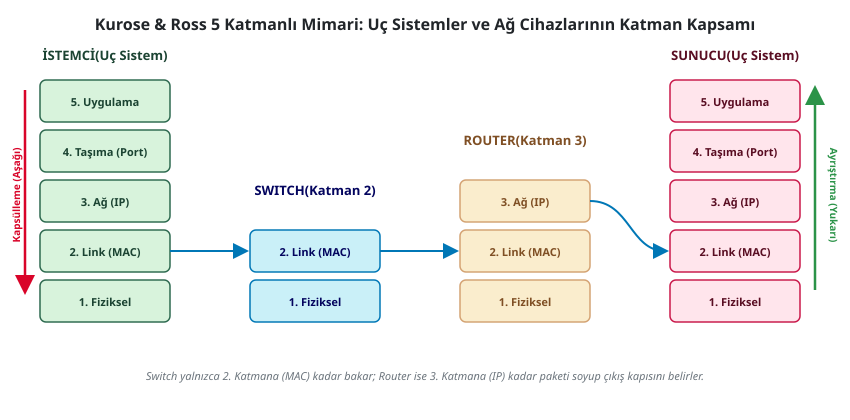

In [1]:
from IPython.display import SVG, display

svg_sema = """
<svg width="850" height="420" viewBox="0 0 850 420" xmlns="http://www.w3.org/2000/svg" style="background:#ffffff; font-family:sans-serif;">
  <defs>
    <!-- Ok Uçları Tanımları -->
    <marker id="arrow-red" markerWidth="8" markerHeight="8" refX="6" refY="4" orient="auto">
      <path d="M 0 0 L 8 4 L 0 8 z" fill="#d90429"/>
    </marker>
    <marker id="arrow-blue" markerWidth="8" markerHeight="8" refX="6" refY="4" orient="auto">
      <path d="M 0 0 L 8 4 L 0 8 z" fill="#0077b6"/>
    </marker>
    <marker id="arrow-green" markerWidth="8" markerHeight="8" refX="6" refY="4" orient="auto">
      <path d="M 0 0 L 8 4 L 0 8 z" fill="#2b9348"/>
    </marker>
  </defs>

  <!-- Başlık -->
  <text x="425" y="30" text-anchor="middle" font-size="16" font-weight="bold" fill="#212529">
    Kurose &amp; Ross 5 Katmanlı Mimari: Uç Sistemler ve Ağ Cihazlarının Katman Kapsamı
  </text>

  <!-- 1. İSTEMCİ (5 Katman) -->
  <g transform="translate(40, 60)">
    <text x="65" y="0" text-anchor="middle" font-size="13" font-weight="bold" fill="#1b4332">İSTEMCİ&#10;(Uç Sistem)</text>
    <rect x="0" y="20" width="130" height="42" rx="6" fill="#d8f3dc" stroke="#2d6a4f" stroke-width="1.5"/>
    <text x="65" y="46" text-anchor="middle" font-size="11" font-weight="bold" fill="#1b4332">5. Uygulama</text>

    <rect x="0" y="70" width="130" height="42" rx="6" fill="#d8f3dc" stroke="#2d6a4f" stroke-width="1.5"/>
    <text x="65" y="96" text-anchor="middle" font-size="11" font-weight="bold" fill="#1b4332">4. Taşıma (Port)</text>

    <rect x="0" y="120" width="130" height="42" rx="6" fill="#d8f3dc" stroke="#2d6a4f" stroke-width="1.5"/>
    <text x="65" y="146" text-anchor="middle" font-size="11" font-weight="bold" fill="#1b4332">3. Ağ (IP)</text>

    <rect x="0" y="170" width="130" height="42" rx="6" fill="#d8f3dc" stroke="#2d6a4f" stroke-width="1.5"/>
    <text x="65" y="196" text-anchor="middle" font-size="11" font-weight="bold" fill="#1b4332">2. Link (MAC)</text>

    <rect x="0" y="220" width="130" height="42" rx="6" fill="#d8f3dc" stroke="#2d6a4f" stroke-width="1.5"/>
    <text x="65" y="246" text-anchor="middle" font-size="11" font-weight="bold" fill="#1b4332">1. Fiziksel</text>
  </g>

  <!-- Kapsülleme Oku (İstemci İçinde Aşağı) -->
  <line x1="25" y1="90" x2="25" y2="290" stroke="#d90429" stroke-width="2.5" marker-end="url(#arrow-red)"/>
  <text x="20" y="195" font-size="10" font-weight="bold" fill="#d90429" transform="rotate(-90 20 195)" text-anchor="middle">Kapsülleme (Aşağı)</text>

  <!-- 2. SWITCH (Katman 2) -->
  <g transform="translate(250, 210)">
    <text x="65" y="-15" text-anchor="middle" font-size="13" font-weight="bold" fill="#03045e">SWITCH&#10;(Katman 2)</text>
    <rect x="0" y="20" width="130" height="42" rx="6" fill="#caf0f8" stroke="#0077b6" stroke-width="1.5"/>
    <text x="65" y="46" text-anchor="middle" font-size="11" font-weight="bold" fill="#03045e">2. Link (MAC)</text>

    <rect x="0" y="70" width="130" height="42" rx="6" fill="#caf0f8" stroke="#0077b6" stroke-width="1.5"/>
    <text x="65" y="96" text-anchor="middle" font-size="11" font-weight="bold" fill="#03045e">1. Fiziksel</text>
  </g>

  <!-- 3. ROUTER (Katman 3) -->
  <g transform="translate(460, 160)">
    <text x="65" y="-15" text-anchor="middle" font-size="13" font-weight="bold" fill="#7f4f24">ROUTER&#10;(Katman 3)</text>
    <rect x="0" y="20" width="130" height="42" rx="6" fill="#faedcd" stroke="#d4a373" stroke-width="1.5"/>
    <text x="65" y="46" text-anchor="middle" font-size="11" font-weight="bold" fill="#7f4f24">3. Ağ (IP)</text>

    <rect x="0" y="70" width="130" height="42" rx="6" fill="#faedcd" stroke="#d4a373" stroke-width="1.5"/>
    <text x="65" y="96" text-anchor="middle" font-size="11" font-weight="bold" fill="#7f4f24">2. Link (MAC)</text>

    <rect x="0" y="120" width="130" height="42" rx="6" fill="#faedcd" stroke="#d4a373" stroke-width="1.5"/>
    <text x="65" y="146" text-anchor="middle" font-size="11" font-weight="bold" fill="#7f4f24">1. Fiziksel</text>
  </g>

  <!-- 4. SUNUCU (5 Katman) -->
  <g transform="translate(670, 60)">
    <text x="65" y="0" text-anchor="middle" font-size="13" font-weight="bold" fill="#590d22">SUNUCU&#10;(Uç Sistem)</text>
    <rect x="0" y="20" width="130" height="42" rx="6" fill="#ffe5ec" stroke="#c9184a" stroke-width="1.5"/>
    <text x="65" y="46" text-anchor="middle" font-size="11" font-weight="bold" fill="#590d22">5. Uygulama</text>

    <rect x="0" y="70" width="130" height="42" rx="6" fill="#ffe5ec" stroke="#c9184a" stroke-width="1.5"/>
    <text x="65" y="96" text-anchor="middle" font-size="11" font-weight="bold" fill="#590d22">4. Taşıma (Port)</text>

    <rect x="0" y="120" width="130" height="42" rx="6" fill="#ffe5ec" stroke="#c9184a" stroke-width="1.5"/>
    <text x="65" y="146" text-anchor="middle" font-size="11" font-weight="bold" fill="#590d22">3. Ağ (IP)</text>

    <rect x="0" y="170" width="130" height="42" rx="6" fill="#ffe5ec" stroke="#c9184a" stroke-width="1.5"/>
    <text x="65" y="196" text-anchor="middle" font-size="11" font-weight="bold" fill="#590d22">2. Link (MAC)</text>

    <rect x="0" y="220" width="130" height="42" rx="6" fill="#ffe5ec" stroke="#c9184a" stroke-width="1.5"/>
    <text x="65" y="246" text-anchor="middle" font-size="11" font-weight="bold" fill="#590d22">1. Fiziksel</text>
  </g>

  <!-- Ayrıştırma Oku (Sunucu İçinde Yukarı) -->
  <line x1="815" y1="290" x2="815" y2="90" stroke="#2b9348" stroke-width="2.5" marker-end="url(#arrow-green)"/>
  <text x="830" y="195" font-size="10" font-weight="bold" fill="#2b9348" transform="rotate(90 830 195)" text-anchor="middle">Ayrıştırma (Yukarı)</text>

  <!-- Cihazlar Arası İletim Okları -->
  <!-- İstemci Link -> Switch Link -->
  <path d="M 170 251 C 210 251, 210 251, 245 251" fill="none" stroke="#0077b6" stroke-width="2" marker-end="url(#arrow-blue)"/>

  <!-- Switch Link -> Router Link/IP -->
  <path d="M 380 251 C 420 251, 420 251, 455 251" fill="none" stroke="#0077b6" stroke-width="2" marker-end="url(#arrow-blue)"/>

  <!-- Router Ağ -> Sunucu Ağ/Link -->
  <path d="M 590 201 C 630 201, 630 251, 665 251" fill="none" stroke="#0077b6" stroke-width="2" marker-end="url(#arrow-blue)"/>

  <!-- Alt Bilgilendirme Notu -->
  <text x="425" y="380" text-anchor="middle" font-size="11" fill="#6c757d" font-style="italic">
    Switch yalnızca 2. Katmana (MAC) kadar bakar; Router ise 3. Katmana (IP) kadar paketi soyup çıkış kapısını belirler.
  </text>
</svg>
"""

display(SVG(svg_sema))

---
## 3. Deney 1: Büyük Verinin Parçalanması (MTU / Segmentation Analizi)

### 3.1. Deneyin Amacı
Uygulama katmanından gelen büyük bir verinin (örneğin 3500 baytlık bir API yanıtı) tek bir parça halinde neden hatta verilemediğini; MTU sınırına göre nasıl segmentlere ayrıldığını, her parçaya nasıl TCP Sequence numarası verildiğini ve toplam paket dizisini görselleştirerek doğrulamak.

C:\WINDOWS\system32\netlab\Lib\site-packages\scapy\layers\tls\crypto\groups.py:25: CryptographyDeprecationWarning: Diffie-Hellman over finite fields (FFDH) is deprecated and support will be removed in a future release. Use a more modern key exchange algorithm.
  from cryptography.hazmat.primitives.asymmetric.dh import DHParameterNumbers


[+] Uygulama Katmanı Toplam Veri : 3835 bayt
[+] İletim Hattı MSS Boyutu       : 1460 bayt
[+] Üretilecek TCP Segment Sayısı : 3 adet

  -> Segment #1  | Payload: 1460 bayt | Toplam: 1514 bayt | Seq No: 10000
  -> Segment #2  | Payload: 1460 bayt | Toplam: 1514 bayt | Seq No: 11460
  -> Segment #3  | Payload: 915  bayt | Toplam: 969  bayt | Seq No: 12920

[+] Paketler 'parcalanmis_akis.pcap' dosyasına kaydedildi.


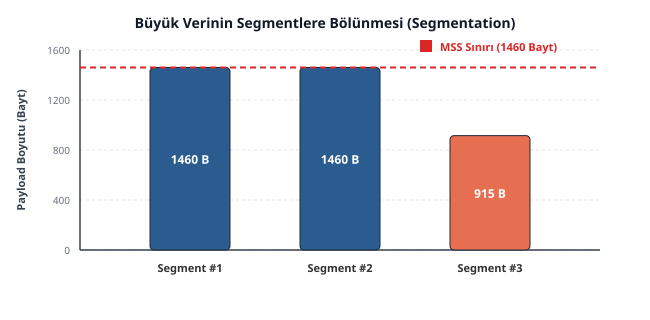

In [2]:
import logging
logging.getLogger("scapy.runtime").setLevel(logging.ERROR)

from scapy.all import Ether, IP, TCP, Raw, wrpcap
from IPython.display import SVG, display

# 1. Senaryo: Uygulama katmanında üretilen 3500 baytlık JSON verisi
raw_json_payload = ("{\"telemetri_verisi\": \"DEGER_BLOKU_XYZ\", \"durum\": \"AKTIF\"}, " * 65).encode('utf-8')
toplam_bayt = len(raw_json_payload)

# Ethernet MTU = 1500 bayt (20B IP + 20B TCP başlığı çıkarılınca MSS = 1460 bayt kalır)
MSS = 1460
paket_sayisi = (toplam_bayt + MSS - 1) // MSS

print(f"[+] Uygulama Katmanı Toplam Veri : {toplam_bayt} bayt")
print(f"[+] İletim Hattı MSS Boyutu       : {MSS} bayt")
print(f"[+] Üretilecek TCP Segment Sayısı : {paket_sayisi} adet\n")

uretilen_paketler = []
segment_boyutlari = []
seq_numaralari = []

for i in range(paket_sayisi):
    baslangic = i * MSS
    bitis = baslangic + MSS
    parca = raw_json_payload[baslangic:bitis]
    
    mevcut_seq = 10000 + baslangic
    seq_numaralari.append(mevcut_seq)
    
    # Paket Kapsülleme (Ethernet + IP + TCP + Payload Parçası)
    pkt = (
        Ether(src="00:1A:2B:3C:4D:5E", dst="AA:BB:CC:DD:EE:FF") /
        IP(src="192.168.1.50", dst="93.184.216.34") /
        TCP(sport=51234, dport=80, seq=mevcut_seq, flags="A") /
        Raw(load=parca)
    )
    uretilen_paketler.append(pkt)
    segment_boyutlari.append(len(parca))
    print(f"  -> Segment #{i+1:<2} | Payload: {len(parca):<4} bayt | Toplam: {len(pkt):<4} bayt | Seq No: {mevcut_seq}")

# Diske Wireshark pcap formatında kaydet
wrpcap("parcalanmis_akis.pcap", uretilen_paketler)
print("\n[+] Paketler 'parcalanmis_akis.pcap' dosyasına kaydedildi.")

# ==============================================================================
# 2. DLL'DEN BAĞIMSIZ DİNAMİK SVG ÇUBUK GRAFİĞİ OLUŞTURMA
# ==============================================================================
chart_w, chart_h = 650, 320
plot_x, plot_y = 80, 50
plot_w, plot_h = 520, 200
y_max = 1600  # Grafiğin üst tavanı (bayt)

# MSS kesikli çizgi Y koordinatı
mss_y = plot_y + plot_h - (MSS / y_max * plot_h)

# Çubukları oluşturma
bars_svg = ""
colors = ["#2b5c8f", "#2b5c8f", "#e76f51"]
bar_w = 80
spacing = (plot_w - (paket_sayisi * bar_w)) / (paket_sayisi + 1)

for idx, val in enumerate(segment_boyutlari):
    bx = plot_x + spacing + idx * (bar_w + spacing)
    bh = (val / y_max) * plot_h
    by = plot_y + plot_h - bh
    color = colors[idx % len(colors)]
    
    bars_svg += f"""
    <!-- Segment #{idx+1} Çubuğu -->
    <rect x="{bx}" y="{by}" width="{bar_w}" height="{bh}" rx="4" fill="{color}" stroke="#1f2937" stroke-width="1"/>
    <text x="{bx + bar_w/2}" y="{by + bh/2 + 5}" fill="#ffffff" font-size="12" font-weight="bold" text-anchor="middle">{val} B</text>
    <text x="{bx + bar_w/2}" y="{plot_y + plot_h + 22}" fill="#333333" font-size="11" font-weight="bold" text-anchor="middle">Segment #{idx+1}</text>
    """

# Y ekseni grid çizgileri ve etiketleri
grid_svg = ""
for y_val in [0, 400, 800, 1200, 1600]:
    gy = plot_y + plot_h - (y_val / y_max * plot_h)
    grid_svg += f"""
    <line x1="{plot_x}" y1="{gy}" x2="{plot_x + plot_w}" y2="{gy}" stroke="#e5e7eb" stroke-dasharray="3,3"/>
    <text x="{plot_x - 10}" y="{gy + 4}" fill="#6b7280" font-size="10" text-anchor="end">{y_val}</text>
    """

svg_content = f"""
<svg width="{chart_w}" height="{chart_h}" viewBox="0 0 {chart_w} {chart_h}" xmlns="http://www.w3.org/2000/svg" style="background:#ffffff; font-family:sans-serif;">
    <!-- Başlık -->
    <text x="{chart_w/2}" y="28" text-anchor="middle" font-size="14" font-weight="bold" fill="#111827">
        Büyük Verinin Segmentlere Bölünmesi (Segmentation)
    </text>
    
    <!-- Grid -->
    {grid_svg}
    
    <!-- Eksenler -->
    <line x1="{plot_x}" y1="{plot_y}" x2="{plot_x}" y2="{plot_y + plot_h}" stroke="#374151" stroke-width="1.5"/>
    <line x1="{plot_x}" y1="{plot_y + plot_h}" x2="{plot_x + plot_w}" y2="{plot_y + plot_h}" stroke="#374151" stroke-width="1.5"/>
    <text x="25" y="{plot_y + plot_h/2}" fill="#374151" font-size="11" font-weight="bold" transform="rotate(-90 25 {plot_y + plot_h/2})" text-anchor="middle">Payload Boyutu (Bayt)</text>
    
    <!-- Çubuklar -->
    {bars_svg}
    
    <!-- MSS Referans Çizgisi -->
    <line x1="{plot_x}" y1="{mss_y}" x2="{plot_x + plot_w}" y2="{mss_y}" stroke="#dc2626" stroke-width="2" stroke-dasharray="6,4"/>
    
    <!-- Legend (Gösterge) -->
    <rect x="{plot_x + plot_w - 180}" y="40" width="12" height="12" fill="#dc2626"/>
    <text x="{plot_x + plot_w - 160}" y="51" fill="#dc2626" font-size="11" font-weight="bold">MSS Sınırı ({MSS} Bayt)</text>
</svg>
"""

display(SVG(svg_content))

---
### 3.2. Deney 1'in Mühendislik Yorumu

1. **Böl ve İlet (Store and Forward):** 3500 baytlık bir veriyi tek bir paket halinde kabloya süremezsiniz. Ağ cihazları (Switch ve Router) gelen paketi çıkış portuna aktarmadan önce belleğe almak zorundadır. Paketlerin küçük ve standart boyutta tutulması kuyruk gecikmelerini ve tampon taşmalarını engeller.
2. **TCP Sıra Numarası (Sequence Number):** Üretilen 3 segmentin Seq numaraları sırasıyla `10000`, `11460` ve `12920` olarak ilerler. Bu değerler rastgele değildir; her segmentin taşıdığı bayt miktarı kadar artar. Ağda paketler sırasız gelse bile alıcı işletim sistemi bu numaralara bakarak veriyi bellekte kusursuz birleştirir.

---
## 4. Deney 2: Katman 2 (Switch) ve Katman 3 (Router) Karar Algoritması

### 4.1. Deneyin Amacı
Bir ağ paketinin Switch tarafından MAC tablosuyla yerel hatta nasıl iletildiğini; Router tarafından ise IP yönlendirme tablosu (Routing Table) ve **En Uzun Eşleşme (Longest Prefix Match)** prensibiyle nasıl dış ağa aktarıldığını kodlayarak ve grafikle modellemek.

--- KATMAN 2: SWITCH TESTLERİ ---
[SWITCH (Katman 2)] -> AA:BB:CC:11:22:33 biliniyor. Paket doğrudan Port 1 (PC-1) portuna iletildi.
[SWITCH (Katman 2)] -> FF:FF:FF:00:11:22 tabloda yok! Paket tüm portlara basıldı (FLOODING).

--- KATMAN 3: ROUTER TESTLERİ ---
[ROUTER (Katman 3)] -> Hedef IP 192.168.1.100, 192.168.1.0/24 kuralına uydu. Çıkış Kapısı: Yerel Ağ Arayüzü (eth0)
[ROUTER (Katman 3)] -> Hedef IP 10.200.5.1, 10.0.0.0/8 kuralına uydu. Çıkış Kapısı: Kampüs / Şirket VPN (tun0)
[ROUTER (Katman 3)] -> Hedef IP 142.250.185.206, 0.0.0.0/0 kuralına uydu. Çıkış Kapısı: Varsayılan Ağ Geçidi / İnternet (wan0)


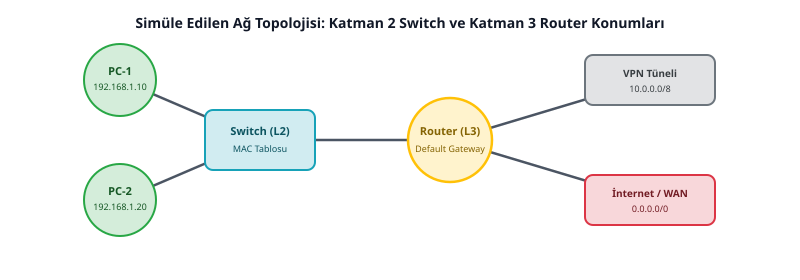

In [3]:
import ipaddress
from IPython.display import SVG, display

# 1. Katman 2: Switch MAC Tablosu (Fiziksel Port -> Cihaz MAC Adresi)
SWITCH_CAM_TABLE = {
    "AA:BB:CC:11:22:33": "Port 1 (PC-1)",
    "AA:BB:CC:44:55:66": "Port 2 (PC-2)",
    "AA:BB:CC:77:88:99": "Port 3 (Yerel Yazıcı)"
}

# 2. Katman 3: Router Yönlendirme Tablosu (Routing Table)
ROUTING_TABLE = [
    {"network": ipaddress.ip_network("192.168.1.0/24"), "gateway": "Yerel Ağ Arayüzü (eth0)"},
    {"network": ipaddress.ip_network("10.0.0.0/8"),      "gateway": "Kampüs / Şirket VPN (tun0)"},
    {"network": ipaddress.ip_network("0.0.0.0/0"),      "gateway": "Varsayılan Ağ Geçidi / İnternet (wan0)"}
]

def switch_forward(dst_mac: str):
    """Katman 2 Kararı: Yalnızca MAC adresine bakar"""
    if dst_mac in SWITCH_CAM_TABLE:
        return f"[SWITCH (Katman 2)] -> {dst_mac} biliniyor. Paket doğrudan {SWITCH_CAM_TABLE[dst_mac]} portuna iletildi."
    else:
        return f"[SWITCH (Katman 2)] -> {dst_mac} tabloda yok! Paket tüm portlara basıldı (FLOODING)."

def router_forward(dst_ip_str: str):
    """Katman 3 Kararı: IP tablosuna ve prefix uzunluğuna bakar"""
    target_ip = ipaddress.ip_address(dst_ip_str)
    for entry in ROUTING_TABLE:
        if target_ip in entry["network"]:
            return f"[ROUTER (Katman 3)] -> Hedef IP {dst_ip_str}, {entry['network']} kuralına uydu. Çıkış Kapısı: {entry['gateway']}"
    return "[ROUTER] -> Rota bulunamadı (Drop)."

print("--- KATMAN 2: SWITCH TESTLERİ ---")
print(switch_forward("AA:BB:CC:11:22:33"))
print(switch_forward("FF:FF:FF:00:11:22"))

print("\n--- KATMAN 3: ROUTER TESTLERİ ---")
print(router_forward("192.168.1.100"))    # Yerel LAN
print(router_forward("10.200.5.1"))       # Şirket VPN
print(router_forward("142.250.185.206")) # Dış İnternet (Google)

# ==============================================================================
# DLL'DEN BAĞIMSIZ VEKTÖREL TOPOLOJİ DİYAGRAMI (SVG)
# ==============================================================================
svg_topoloji = """
<svg width="800" height="280" viewBox="0 0 800 280" xmlns="http://www.w3.org/2000/svg" style="background:#ffffff; font-family:sans-serif;">
  <!-- Başlık -->
  <text x="400" y="28" text-anchor="middle" font-size="14" font-weight="bold" fill="#111827">
    Simüle Edilen Ağ Topolojisi: Katman 2 Switch ve Katman 3 Router Konumları
  </text>

  <!-- Bağlantı Çizgileri (Edges) -->
  <line x1="120" y1="80" x2="260" y2="140" stroke="#4b5563" stroke-width="2.5"/>
  <line x1="120" y1="200" x2="260" y2="140" stroke="#4b5563" stroke-width="2.5"/>
  <line x1="260" y1="140" x2="450" y2="140" stroke="#4b5563" stroke-width="2.5"/>
  <line x1="450" y1="140" x2="650" y2="80" stroke="#4b5563" stroke-width="2.5"/>
  <line x1="450" y1="140" x2="650" y2="200" stroke="#4b5563" stroke-width="2.5"/>

  <!-- Düğüm 1: PC-1 -->
  <g transform="translate(120, 80)">
    <circle r="36" fill="#d4edda" stroke="#28a745" stroke-width="2"/>
    <text y="-5" text-anchor="middle" font-size="11" font-weight="bold" fill="#155724">PC-1</text>
    <text y="10" text-anchor="middle" font-size="9" fill="#155724">192.168.1.10</text>
  </g>

  <!-- Düğüm 2: PC-2 -->
  <g transform="translate(120, 200)">
    <circle r="36" fill="#d4edda" stroke="#28a745" stroke-width="2"/>
    <text y="-5" text-anchor="middle" font-size="11" font-weight="bold" fill="#155724">PC-2</text>
    <text y="10" text-anchor="middle" font-size="9" fill="#155724">192.168.1.20</text>
  </g>

  <!-- Düğüm 3: Switch (Katman 2) -->
  <g transform="translate(260, 140)">
    <rect x="-55" y="-30" width="110" height="60" rx="8" fill="#d1ecf1" stroke="#17a2b8" stroke-width="2"/>
    <text y="-5" text-anchor="middle" font-size="11" font-weight="bold" fill="#0c5460">Switch (L2)</text>
    <text y="12" text-anchor="middle" font-size="9" fill="#0c5460">MAC Tablosu</text>
  </g>

  <!-- Düğüm 4: Router (Katman 3) -->
  <g transform="translate(450, 140)">
    <circle r="42" fill="#fff3cd" stroke="#ffc107" stroke-width="2.5"/>
    <text y="-5" text-anchor="middle" font-size="11" font-weight="bold" fill="#856404">Router (L3)</text>
    <text y="12" text-anchor="middle" font-size="9" fill="#856404">Default Gateway</text>
  </g>

  <!-- Düğüm 5: VPN Tüneli -->
  <g transform="translate(650, 80)">
    <rect x="-65" y="-25" width="130" height="50" rx="8" fill="#e2e3e5" stroke="#6c757d" stroke-width="2"/>
    <text y="-3" text-anchor="middle" font-size="10" font-weight="bold" fill="#383d41">VPN Tüneli</text>
    <text y="12" text-anchor="middle" font-size="9" fill="#383d41">10.0.0.0/8</text>
  </g>

  <!-- Düğüm 6: İnternet / WAN -->
  <g transform="translate(650, 200)">
    <rect x="-65" y="-25" width="130" height="50" rx="8" fill="#f8d7da" stroke="#dc3545" stroke-width="2"/>
    <text y="-3" text-anchor="middle" font-size="10" font-weight="bold" fill="#721c24">İnternet / WAN</text>
    <text y="12" text-anchor="middle" font-size="9" fill="#721c24">0.0.0.0/0</text>
  </g>
</svg>
"""

display(SVG(svg_topoloji))

---
### 4.2. Deney 2'nin Mühendislik Yorumu

1. **Switch ve Güvenlik Zaafı (Flooding):** Switch hedef MAC'i tanımıyorsa paketi o ağdaki tüm portlara fırlatır (`Flooding`). Bu durum, aynı switch'e bağlı bir saldırganın yerel ağdaki trafiği pasif olarak dinleyebilmesine (Sniffing) imkan tanır.
2. **Router ve Varsayılan Ağ Geçidi:** Router'ların internetteki milyarlarca IP adresini tek tek listelemesi mümkün değildir. `0.0.0.0/0` kuralı sayesinde yerel ağda olmayan tüm hedefler doğrudan ISS yönlendiricisine iletilir.

---
## 5. Laboratuvar Uygulaması: İstemci-Sunucu HTTP Oturumunun Katmanlı Analizi

### 5.1. Uygulamanın Amacı
Kurose & Ross Bölüm 1.5'te yer alan istemci-sunucu modelini doğrulamak üzere; tarayıcının attığı `HTTP GET` isteği ile sunucunun döndüğü `HTTP 200 OK` yanıtını iki yönlü olarak Scapy ile inşa etmek, port ve IP değişimlerini incelemek ve üretilen paket akışını diske `.pcap` olarak yazıp ayrıştırmaktır.

### 5.2. Yönerge
1. **İstemci Paketi (Request):**
   * Katman 2 (Ethernet): Kaynak MAC `AA:AA:AA:AA:AA:AA`, Hedef MAC `BB:BB:BB:BB:BB:BB`
   * Katman 3 (IP): Kaynak IP `192.168.1.10`, Hedef IP `93.184.216.34` (example.com)
   * Katman 4 (TCP): Kaynak Port `52100` (Ephemeral Port), Hedef Port `80` (HTTP Sunucu Portu), Bayraklar `PA` (Push-Ack)
   * Katman 5 (Uygulama): `GET /index.html HTTP/1.1\r\nHost: example.com\r\n\r\n`
2. **Sunucu Paketi (Response):**
   * Adres ve port rollerini tersine çevirin (Kaynak `80`, Hedef `52100`).
   * Katman 5: `HTTP/1.1 200 OK\r\nContent-Length: 12\r\n\r\nHello World!`
3. Her iki paketi tek bir `.pcap` dosyasında birleştirip kaydedin ve Python ile katman başlıklarını ekrana yazdırın.

In [4]:
# ==============================================================================
# UYGULAMA: İstemci-Sunucu HTTP Trafiği İnşası ve Oturum Analizi
# ==============================================================================
from scapy.all import Ether, IP, TCP, Raw, wrpcap, rdpcap

# 1. İstemci İstek Paketi (Client -> Server)
req_payload = b"GET /index.html HTTP/1.1\r\nHost: example.com\r\n\r\n"
req_packet = (
    Ether(src="AA:AA:AA:AA:AA:AA", dst="BB:BB:BB:BB:BB:BB") /
    IP(src="192.168.1.10", dst="93.184.216.34") /
    TCP(sport=52100, dport=80, flags="PA", seq=100, ack=1) /
    Raw(load=req_payload)
)

# 2. Sunucu Yanıt Paketi (Server -> Client)
res_payload = b"HTTP/1.1 200 OK\r\nContent-Length: 12\r\n\r\nHello World!"
res_packet = (
    Ether(src="BB:BB:BB:BB:BB:BB", dst="AA:AA:AA:AA:AA:AA") /
    IP(src="93.184.216.34", dst="192.168.1.10") /
    TCP(sport=80, dport=52100, flags="PA", seq=1, ack=100 + len(req_payload)) /
    Raw(load=res_payload)
)

# 3. İki yönlü iletişimi .pcap dosyasına kaydedelim
pcap_dosyasi = "http_oturum_akisi.pcap"
wrpcap(pcap_dosyasi, [req_packet, res_packet])
print(f"[+] HTTP oturumu '{pcap_dosyasi}' dosyasına başarıyla yazıldı.\n")

# 4. Dosyadan paketleri okuyup ayrıştırma (Decapsulation)
okunan_oturum = rdpcap(pcap_dosyasi)

for idx, paket in enumerate(okunan_oturum, start=1):
    yon = "İSTEMCİ -> SUNUCU (HTTP İSTEK)" if paket[TCP].dport == 80 else "SUNUCU -> İSTEMCİ (HTTP YANIT)"
    print("=" * 70)
    print(f"PAKET #{idx}: {yon}")
    print("=" * 70)
    print(f"  [Katman 2 - Link]       : {paket[Ether].src} -> {paket[Ether].dst}")
    print(f"  [Katman 3 - Ağ/IP]      : {paket[IP].src} -> {paket[IP].dst} (TTL: {paket[IP].ttl})")
    print(f"  [Katman 4 - Taşıma/TCP] : Port {paket[TCP].sport} -> Port {paket[TCP].dport} | Flags: {paket[TCP].flags}")
    print(f"  [Katman 5 - Uygulama]   :\n{paket[Raw].load.decode('utf-8', errors='ignore')}")
print("=" * 70)

[+] HTTP oturumu 'http_oturum_akisi.pcap' dosyasına başarıyla yazıldı.

PAKET #1: İSTEMCİ -> SUNUCU (HTTP İSTEK)
  [Katman 2 - Link]       : aa:aa:aa:aa:aa:aa -> bb:bb:bb:bb:bb:bb
  [Katman 3 - Ağ/IP]      : 192.168.1.10 -> 93.184.216.34 (TTL: 64)
  [Katman 4 - Taşıma/TCP] : Port 52100 -> Port 80 | Flags: PA
  [Katman 5 - Uygulama]   :
GET /index.html HTTP/1.1
Host: example.com


PAKET #2: SUNUCU -> İSTEMCİ (HTTP YANIT)
  [Katman 2 - Link]       : bb:bb:bb:bb:bb:bb -> aa:aa:aa:aa:aa:aa
  [Katman 3 - Ağ/IP]      : 93.184.216.34 -> 192.168.1.10 (TTL: 64)
  [Katman 4 - Taşıma/TCP] : Port 80 -> Port 52100 | Flags: PA
  [Katman 5 - Uygulama]   :
HTTP/1.1 200 OK
Content-Length: 12

Hello World!


---
### 5.3. Konsol Çıktısı ve Mühendislik Analizi

```text
======================================================================
PAKET #1: İSTEMCİ -> SUNUCU (HTTP İSTEK)
======================================================================
  [Katman 2 - Link]       : aa:aa:aa:aa:aa:aa -> bb:bb:bb:bb:bb:bb
  [Katman 3 - Ağ/IP]      : 192.168.1.10 -> 93.184.216.34 (TTL: 64)
  [Katman 4 - Taşıma/TCP] : Port 52100 -> Port 80 | Flags: PA
  [Katman 5 - Uygulama]   :
GET /index.html HTTP/1.1
Host: example.com


======================================================================
PAKET #2: SUNUCU -> İSTEMCİ (HTTP YANIT)
======================================================================
  [Katman 2 - Link]       : bb:bb:bb:bb:bb:bb -> aa:aa:aa:aa:aa:aa
  [Katman 3 - Ağ/IP]      : 93.184.216.34 -> 192.168.1.10 (TTL: 64)
  [Katman 4 - Taşıma/TCP] : Port 80 -> Port 52100 | Flags: PA
  [Katman 5 - Uygulama]   :
HTTP/1.1 200 OK
Content-Length: 12

Hello World!
======================================================================
```

#### Mühendislik Yorumu:
1. **Portların Rol Değişimi:** İstek paketinde hedef port `80` (Web sunucusu), kaynak port ise istemcinin dinamik portudur (`52100`). Yanıt paketinde bu roller yer değiştirir. İşletim sistemi bu sayede gelen yanıtı arka planda bekleyen doğru tarayıcı sekmesine yönlendirir.
2. **Metin Saydamlığı ve Güvenlik Zaafı:** Katman 5 verisi incelendiğinde `GET /index.html` ve `Hello World!` metinlerinin kabloda tamamen açık (Plain Text) aktığı görülür. Katman 2 veya 3 üzerinde araya giren herhangi bir gözlemci içeriği doğrudan okuyabilir. Bu durum, ilerleyen haftalarda inceleyeceğimiz **TLS/HTTPS** şifrelemesinin neden zorunlu olduğunu somut olarak kanıtlar.